In [19]:
import json
import pandas as pd
from pathlib import Path
from pyesgf.search import SearchConnection

In [2]:
required_vars = ["tas", "huss", "pr", "rsds", "va100m", "ua100m", 
                 "va150m", "ua150m", "va200m", "ua200m", "hurs", "mrro"]

In [3]:
paths = json.load(open("../paths.json"))
path_data_cordex = Path(paths["path_data_cordex"])

# Availability on ESGF

In [4]:
from pyesgf.search import SearchConnection
import pandas as pd

# ESGF search URL (DKRZ Node)
ESGF_URL = "https://esgf-data.dkrz.de/esg-search"

# Connect to ESGF
conn = SearchConnection(ESGF_URL, distrib=True)

# Define variables of interest
variables_of_interest = ["va100m", "ua100m", "va150m", "ua150m", "va200m", "ua200m", "mrro"]

# Search for EURO-CORDEX EUR-11 datasets
ctx = conn.new_context(
    project="CORDEX",
    domain="EUR-11",
    variable=variables_of_interest,
    facets="*",  # Request all facets
)

print(f"Total Hits: {ctx.hit_count}")

# Initialize list to collect dataset info
dataset_info = []

# Iterate over each dataset result
for result in ctx.search():
    # Extract metadata
    model = result.json.get('driving_model', 'Unknown')[0]
    experiment = result.json.get('experiment', 'Unknown')[0]
    variable = result.json.get('variable', 'Unknown')[0]
    rcm_name = result.json.get('rcm_name', 'Unknown')[0]
    resolution = result.json.get('domain', 'Unknown')[0]
    frequency = result.json.get('time_frequency', 'Unknown')[0]
    institute = result.json.get('institute', 'Unknown')[0]

    local_path = path_data_cordex / experiment / frequency / variable / institute / model / f"{institute}-{rcm_name}"
    
    # Append to list
    dataset_info.append({
        "Variable": variable,
        "Experiment": experiment,
        "Institute": institute,
        "Driving Model": model,
        "RCM": rcm_name,
        "Frequency": frequency,
        "Resolution": resolution,
        "Local_Path": str(local_path),
        "Exists_Locally": local_path.exists()
    })

# Convert to DataFrame
df = pd.DataFrame(dataset_info)

# Display DataFrame
df.head()

Total Hits: 805


,Variable,Experiment,Institute,Driving Model,RCM,Frequency,Resolution,Local_Path,Exists_Locally
0,mrro,historical,MOHC,CNRM-CERFACS-CNRM-CM5,HadREM3-GA7-05,6hr,EUR-11,/net/atmos/data/cordex/EUR-11/historical/6hr/m...,False
1,mrro,historical,MOHC,CNRM-CERFACS-CNRM-CM5,HadREM3-GA7-05,day,EUR-11,/net/atmos/data/cordex/EUR-11/historical/day/m...,True
2,mrro,historical,MOHC,CNRM-CERFACS-CNRM-CM5,HadREM3-GA7-05,mon,EUR-11,/net/atmos/data/cordex/EUR-11/historical/mon/m...,True
3,mrro,historical,MOHC,CNRM-CERFACS-CNRM-CM5,HadREM3-GA7-05,sem,EUR-11,/net/atmos/data/cordex/EUR-11/historical/sem/m...,True
4,mrro,rcp85,MOHC,CNRM-CERFACS-CNRM-CM5,HadREM3-GA7-05,6hr,EUR-11,/net/atmos/data/cordex/EUR-11/rcp85/6hr/mrro/M...,False


In [12]:
df[(df["Variable"] == "mrro") & (df["Frequency"] == "day") & (df["Experiment"] == "rcp45") & (df["Institute"].isin(["MOHC", "CNRM"]))]

,Variable,Experiment,Institute,Driving Model,RCM,Frequency,Resolution,Local_Path,Exists_Locally
75,mrro,rcp45,CNRM,CNRM-CERFACS-CNRM-CM5,ALADIN53,day,EUR-11,/net/atmos/data/cordex/EUR-11/rcp45/day/mrro/C...,True
89,mrro,rcp45,CNRM,CNRM-CERFACS-CNRM-CM5,ALADIN63,day,EUR-11,/net/atmos/data/cordex/EUR-11/rcp45/day/mrro/C...,True


In [15]:
df[(df["Variable"] == "va100m") & (df["Frequency"] == "3hr") & (df["Experiment"] == "rcp26") & (df["Institute"].isin(["MOHC", "CNRM"]))]

,Variable,Experiment,Institute,Driving Model,RCM,Frequency,Resolution,Local_Path,Exists_Locally


# Availability on IAC Servers

In [53]:
df_on_server = df[df["Exists_Locally"] == True]

In [41]:
import sys
sys.path.append("..")
from src.utils_xarray import (
    get_time_resolution
)
get_time_resolution(xr.open_zarr(Path(paths["path_data_processed"]) / 
                  "cerra_processed" /  
                  "regridded" / 
                  "ssrd.zarr")).total_seconds() / 3600

3.0

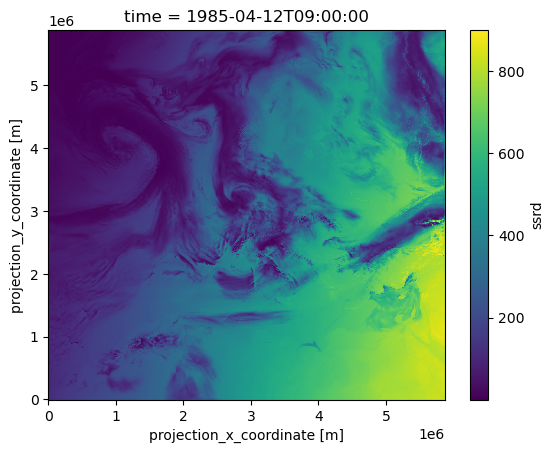

In [70]:
((xr.open_dataset(sorted((Path(paths["path_data_cerra"]) / "original" / "ssrd").glob("*"))[0]).ssrd.isel(time=810)) / (3 * 3600)).plot() 

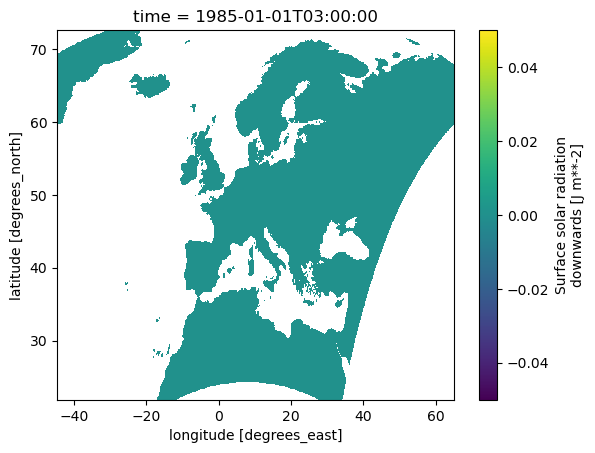

In [48]:
(xr.open_zarr(Path(paths["path_data_processed"]) / 
                  "cerra_processed" /  
                  "regridded" / 
                  "ssrd.zarr")).ssrd.isel(time=0).plot()

In [76]:
import numpy as np
ds_ssrd = (xr.open_zarr(Path(paths["path_data_processed"]) / 
                  "cerra_processed" /  
                  "regridded" / 
                  "ssrd.zarr"))
mask_ssrd_land = ~np.isnan(ds_ssrd['ssrd'].isel(time=0))

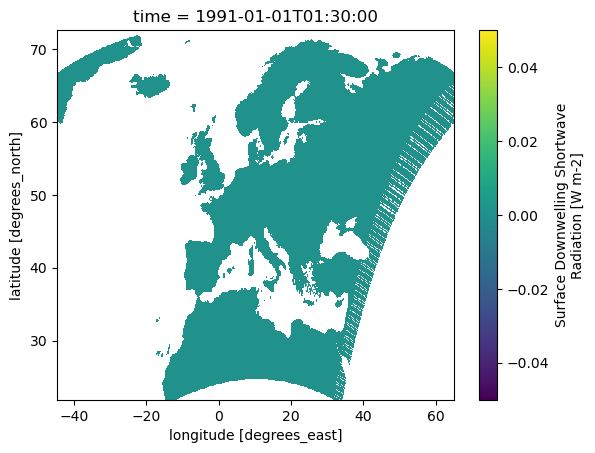

In [81]:
import xarray as xr
xr.open_zarr(Path(paths["path_data_processed"]) / 
                  "cordex_processed" / 
                  "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85" / 
                  "regridded" / 
                  "3hr" / "rsds.zarr").where(mask_ssrd_land).isel(time=0).load().rsds.plot()